<a href="https://colab.research.google.com/github/panarisivalentino-pixel/analisis-juegos-steam/blob/main/notebooks/05_regresion_peak_ccu.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Matriz Utilizada:

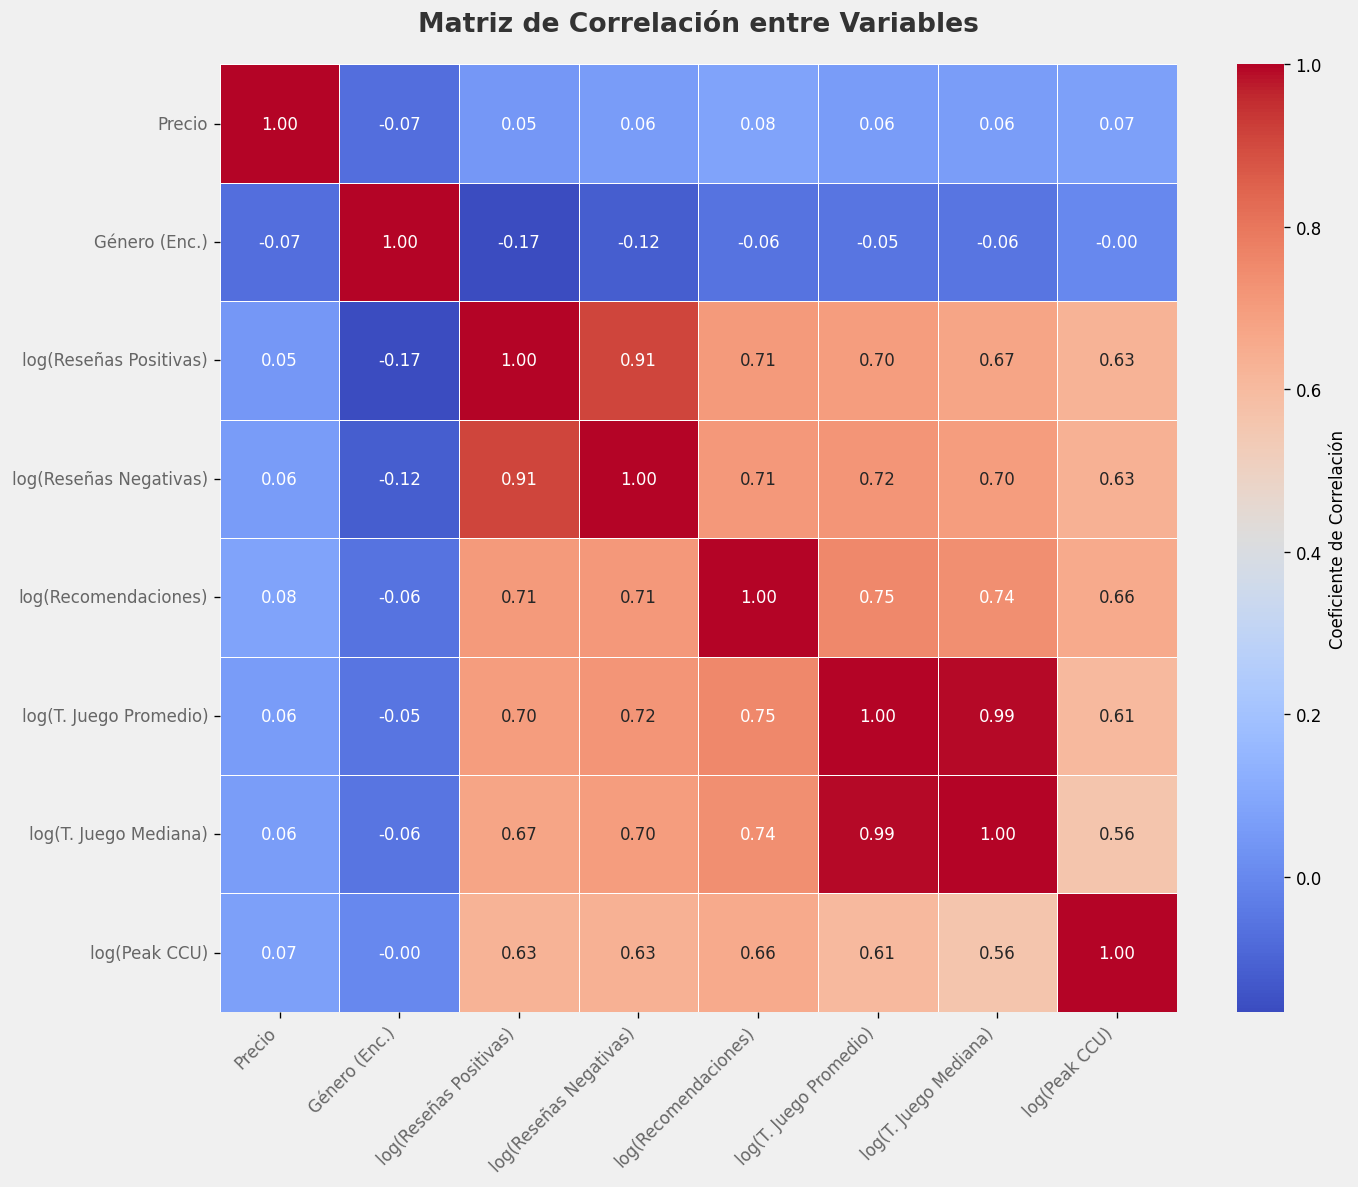

In [ ]:
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import LabelEncoder

# Define plotting style variables (assuming they are not defined elsewhere)
BG = '#F0F0F0' # Light grey background
TEXTO = '#333333' # Dark grey text
GRIS = '#666666' # Medium grey for axis labels

# Define the numerical features to be considered from the original 'df'
# These are the base names before any log transformation
original_numeric_cols_for_log = [
    'Positive2',
    'Negative',
    'Recommendations2',
    'Average playtime forever',
    'Median playtime forever',
]
# Other numerical features not logged, but included
other_numeric_cols = ['Price']

# Combine all base features that will be used for df_corr selection, including 'Genre' for encoding
initial_features_for_df_corr = original_numeric_cols_for_log + other_numeric_cols + ['Peak CCU']

# --- Handle 'Genero_Enc' creation ---
# If 'Genre' column exists and 'Genero_Enc' is not yet created, create it
if 'Genre' in df.columns and 'Genero_Enc' not in df.columns:
    # Use the first genre found for each game (assuming comma-separated list)
    df['Primary_Genre'] = df['Genre'].apply(lambda x: str(x).split(',')[0].strip() if pd.notna(x) and x else 'Unknown')
    le = LabelEncoder()
    df['Genero_Enc'] = le.fit_transform(df['Primary_Genre'])
    # Add 'Genero_Enc' to the features to be selected for df_corr
    initial_features_for_df_corr.append('Genero_Enc')
elif 'Genero_Enc' in df.columns: # If 'Genero_Enc' already exists in df
    initial_features_for_df_corr.append('Genero_Enc')
# If 'Genre' is also missing and 'Genero_Enc' is not there, it will be skipped from correlation.

# Create df_corr with selected columns from df
df_corr = df[initial_features_for_df_corr].copy()

# Apply log1p transformation to relevant columns and rename them
for col in original_numeric_cols_for_log + ['Peak CCU']:
    if col in df_corr.columns:
        df_corr[f'log_{col}'] = np.log1p(df_corr[col])
        df_corr = df_corr.drop(columns=[col])

# Ensure 'Genero_Enc' is float if it's in df_corr
if 'Genero_Enc' in df_corr.columns:
    df_corr['Genero_Enc'] = df_corr['Genero_Enc'].astype(float)

# Renombrar columnas para el gráfico (usando los nombres bonitos de los coeficientes)
# The keys here are the actual column names in df_corr after transformations
corr_columns_map = {
    'log_Positive2': 'log(Reseñas Positivas)',
    'log_Negative': 'log(Reseñas Negativas)',
    'log_Recommendations2': 'log(Recomendaciones)',
    'log_Average playtime forever': 'log(T. Juego Promedio)',
    'log_Median playtime forever': 'log(T. Juego Mediana)',
    'Price': 'Precio',
    'Genero_Enc': 'Género (Enc.)',
    'log_Peak CCU': 'log(Peak CCU)' # Corrected key to match the transformed column name
}
df_corr = df_corr.rename(columns=corr_columns_map)

# Calcular la matriz de correlación
correlation_matrix = df_corr.corr()

# Configurar el estilo del gráfico
plt.figure(figsize=(12, 10), facecolor=BG)
sns.heatmap(
    correlation_matrix,
    annot=True, # Mostrar los valores de correlación en el mapa de calor
    cmap='coolwarm', # Elegir un mapa de color divergente
    fmt=".2f", # Formato de dos decimales para los valores
    linewidths=.5, # Añadir líneas entre las celdas
    linecolor='white',
    cbar_kws={'label': 'Coeficiente de Correlación'}
)
plt.title('Matriz de Correlación entre Variables', fontsize=16, fontweight='bold', color=TEXTO, pad=20)
plt.xticks(rotation=45, ha='right', fontsize=10, color=GRIS)
plt.yticks(rotation=0, fontsize=10, color=GRIS)
plt.tight_layout()
plt.show()

# Regresión Lineal: Predicción de Peak CCU en Steam

Este notebook entrena un modelo de regresión lineal para predecir el **Peak CCU** (pico de usuarios simultáneos) de un juego en Steam usando las reseñas positivas y negativas como predictores.

Todas las variables se transforman con `log` para estabilizar la varianza, siguiendo lo observado en la matriz de correlación.


In [ ]:
# Instalación de dependencias (descomentar si es necesario)
# !pip install pandas numpy matplotlib seaborn scikit-learn scipy


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from scipy import stats

plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.family'] = 'DejaVu Sans'


## 1. Carga y exploración de datos

In [ ]:
# Subí el CSV a Colab usando el panel de archivos (ícono de carpeta a la izquierda)
# o descomenta la línea de abajo para subirlo manualmente:
# from google.colab import files; files.upload()

df = pd.read_csv('cleaned_games_data.csv', low_memory=False)
print(f"Filas totales: {len(df):,}")
print(f"Columnas: {list(df.columns)}")
df[['Peak CCU', 'Positive2', 'Negative']].describe()


Filas totales: 120,919
Columnas: ['Name', 'Release date', 'Peak CCU', 'Required age', 'Price', 'Supported languages', ' audio languages', 'Windows2', 'Mac', 'Linux2', 'Positive2', 'Negative', 'Recommendations2', 'Average playtime forever', 'Median playtime forever', 'Publishers', 'Genre']


,Peak CCU,Positive2,Negative
count,1.209190e+05,1.209190e+05,1.209190e+05
mean,5.529158e+01,1.058286e+03,1.712897e+02
std,3.755434e+03,2.828721e+04,5.412057e+03
min,0.000000e+00,0.000000e+00,0.000000e+00
25%,0.000000e+00,0.000000e+00,0.000000e+00
50%,0.000000e+00,5.000000e+00,1.000000e+00
75%,0.000000e+00,3.700000e+01,1.100000e+01
max,1.013936e+06,7.642084e+06,1.173003e+06


## 2. Preprocesamiento: filtrado y transformación logarítmica

In [ ]:
# Filtrar registros con valores > 0 en las tres variables clave
df_clean = df[(df['Peak CCU'] > 0) & (df['Positive2'] > 0) & (df['Negative'] > 0)].copy()
print(f"Juegos con datos válidos: {len(df_clean):,} (de {len(df):,})")

# Transformación logarítmica
df_clean['log_peak_ccu']  = np.log(df_clean['Peak CCU'])
df_clean['log_positive']  = np.log(df_clean['Positive2'])
df_clean['log_negative']  = np.log(df_clean['Negative'])

df_clean[['log_peak_ccu', 'log_positive', 'log_negative']].describe().round(3)


Juegos con datos válidos: 17,872 (de 120,919)


,log_peak_ccu,log_positive,log_negative
count,17872.000,17872.000,17872.000
mean,1.814,6.055,4.322
std,2.021,2.188,2.153
min,0.000,0.000,0.000
25%,0.000,4.477,2.773
50%,1.099,5.956,4.304
75%,2.833,7.477,5.753
max,13.829,15.849,13.975


### Distribuciones después de la transformación log

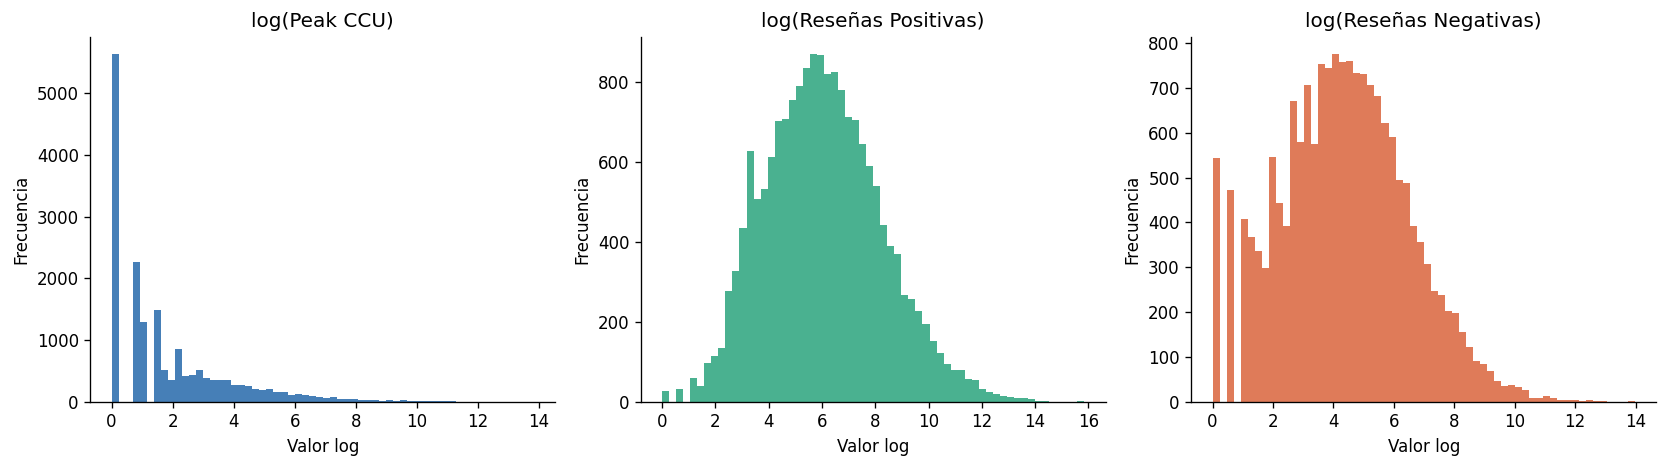

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
vars_plot = [
    ('log_peak_ccu',  'log(Peak CCU)',           '#185FA5'),
    ('log_positive',  'log(Reseñas Positivas)',   '#1D9E75'),
    ('log_negative',  'log(Reseñas Negativas)',   '#D85A30'),
]
for ax, (col, label, color) in zip(axes, vars_plot):
    ax.hist(df_clean[col], bins=60, color=color, alpha=0.8, edgecolor='none')
    ax.set_title(label, fontsize=12)
    ax.set_xlabel('Valor log')
    ax.set_ylabel('Frecuencia')
    ax.spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.show()


## 3. Correlaciones entre variables

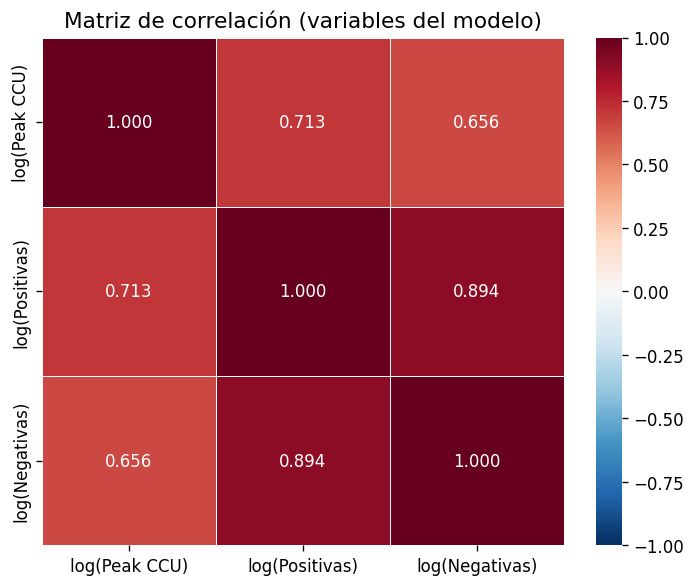

In [ ]:
corr_vars = df_clean[['log_peak_ccu', 'log_positive', 'log_negative']]
corr_matrix = corr_vars.corr()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    corr_matrix, annot=True, fmt='.3f', cmap='RdBu_r',
    vmin=-1, vmax=1, ax=ax, linewidths=0.5,
    xticklabels=['log(Peak CCU)', 'log(Positivas)', 'log(Negativas)'],
    yticklabels=['log(Peak CCU)', 'log(Positivas)', 'log(Negativas)']
)
ax.set_title('Matriz de correlación (variables del modelo)', fontsize=13)
plt.tight_layout()
plt.show()


## 4. Entrenamiento del modelo

In [ ]:
X = df_clean[['log_positive', 'log_negative']]
y = df_clean['log_peak_ccu']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f"Train: {len(X_train):,} juegos | Test: {len(X_test):,} juegos")

model = LinearRegression()
model.fit(X_train, y_train)

y_pred_train = model.predict(X_train)
y_pred_test  = model.predict(X_test)

r2_train = r2_score(y_train, y_pred_train)
r2_test  = r2_score(y_test, y_pred_test)
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))

print(f"\n{'='*40}")
print(f"  Intercepto:              {model.intercept_:.4f}")
print(f"  Coef. log(Positivas):    {model.coef_[0]:.4f}")
print(f"  Coef. log(Negativas):    {model.coef_[1]:.4f}")
print(f"{'='*40}")
print(f"  R²  (train):             {r2_train:.4f}")
print(f"  R²  (test):              {r2_test:.4f}")
print(f"  RMSE (test, log scale):  {rmse_test:.4f}")
print(f"{'='*40}")
print(f"\nEcuación:")
print(f"  log(Peak CCU) = {model.intercept_:.4f}")
print(f"                 + {model.coef_[0]:.4f} × log(Reseñas Positivas)")
print(f"                 + {model.coef_[1]:.4f} × log(Reseñas Negativas)")


Train: 14,297 juegos | Test: 3,575 juegos

  Intercepto:              -2.0636
  Coef. log(Positivas):    0.5700
  Coef. log(Negativas):    0.0982
  R²  (train):             0.5060
  R²  (test):              0.5243
  RMSE (test, log scale):  1.3812

Ecuación:
  log(Peak CCU) = -2.0636
                 + 0.5700 × log(Reseñas Positivas)
                 + 0.0982 × log(Reseñas Negativas)


## 5. Diagnóstico del modelo

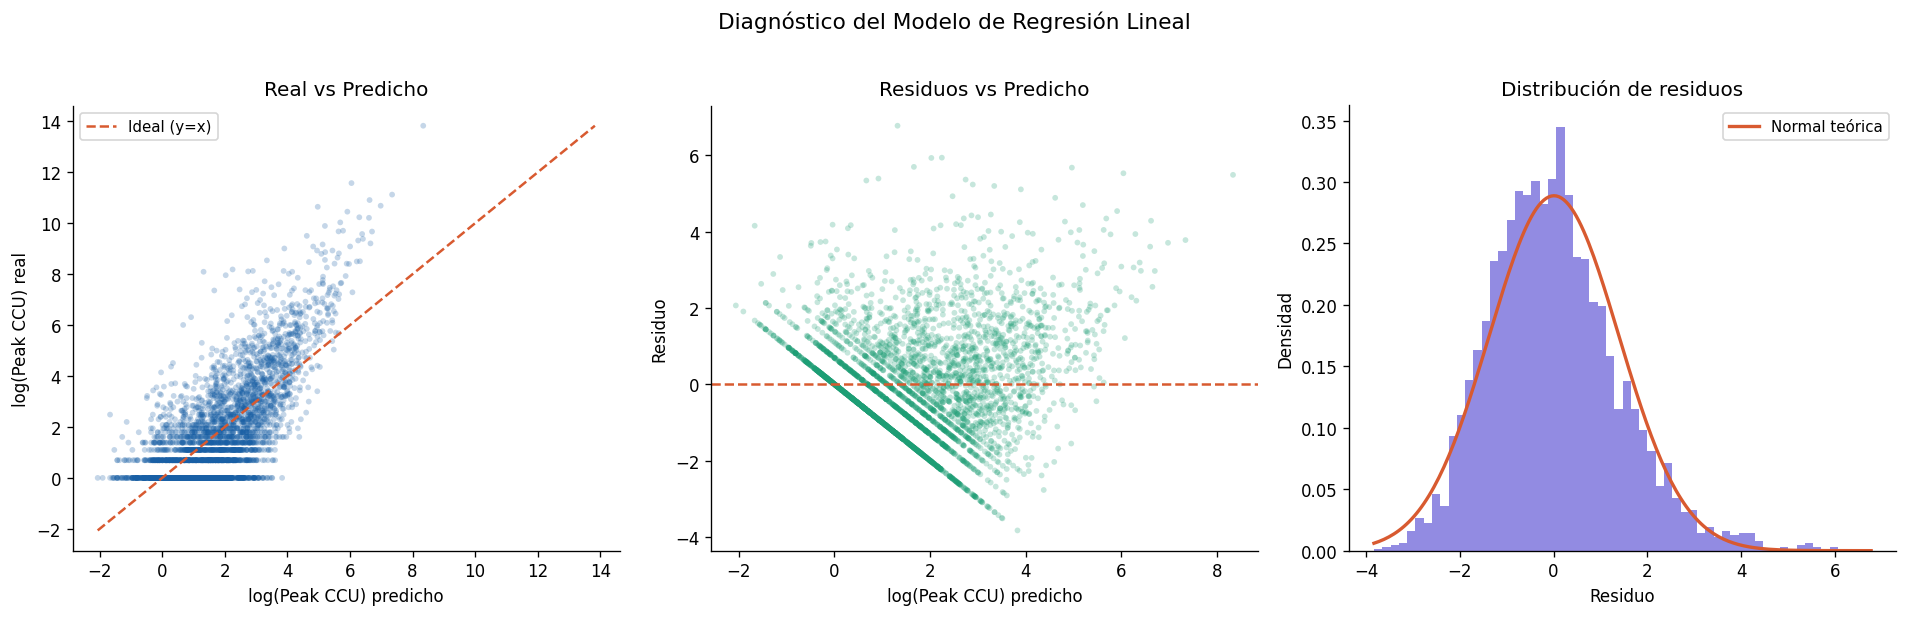

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# -- Scatter: real vs predicho
ax = axes[0]
ax.scatter(y_pred_test, y_test, alpha=0.25, s=12, color='#185FA5', edgecolors='none')
lims = [min(y_test.min(), y_pred_test.min()), max(y_test.max(), y_pred_test.max())]
ax.plot(lims, lims, '--', color='#D85A30', linewidth=1.5, label='Ideal (y=x)')
ax.set_xlabel('log(Peak CCU) predicho')
ax.set_ylabel('log(Peak CCU) real')
ax.set_title('Real vs Predicho')
ax.legend(fontsize=9)
ax.spines[['top','right']].set_visible(False)

# -- Residuos vs predicho
residuals = y_test - y_pred_test
ax = axes[1]
ax.scatter(y_pred_test, residuals, alpha=0.25, s=12, color='#1D9E75', edgecolors='none')
ax.axhline(0, color='#D85A30', linewidth=1.5, linestyle='--')
ax.set_xlabel('log(Peak CCU) predicho')
ax.set_ylabel('Residuo')
ax.set_title('Residuos vs Predicho')
ax.spines[['top','right']].set_visible(False)

# -- Histograma de residuos
ax = axes[2]
ax.hist(residuals, bins=60, color='#7F77DD', alpha=0.85, edgecolor='none', density=True)
xr = np.linspace(residuals.min(), residuals.max(), 200)
ax.plot(xr, stats.norm.pdf(xr, residuals.mean(), residuals.std()),
        color='#D85A30', linewidth=2, label='Normal teórica')
ax.set_xlabel('Residuo')
ax.set_ylabel('Densidad')
ax.set_title('Distribución de residuos')
ax.legend(fontsize=9)
ax.spines[['top','right']].set_visible(False)

plt.suptitle('Diagnóstico del Modelo de Regresión Lineal', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()


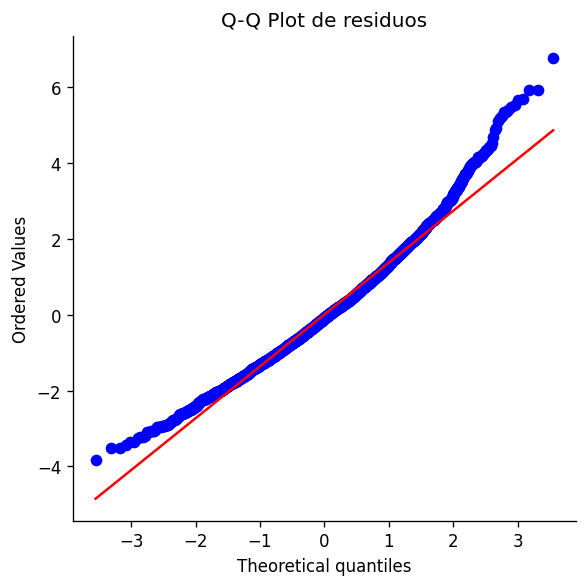

In [ ]:
fig, ax = plt.subplots(figsize=(5, 5))
stats.probplot(residuals, dist='norm', plot=ax)
ax.set_title('Q-Q Plot de residuos')
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()


## 6. Calculadora de predicción

In [ ]:
def predecir_peak_ccu(resenas_positivas: int, resenas_negativas: int) -> dict:
    """
    Predice el Peak CCU de un juego en Steam.

    Parámetros
    ----------
    resenas_positivas : int  — cantidad de reseñas positivas
    resenas_negativas : int  — cantidad de reseñas negativas

    Retorna
    -------
    dict con la predicción central e intervalo ±1 RMSE (en usuarios reales)
    """
    assert resenas_positivas > 0 and resenas_negativas > 0, "Los valores deben ser > 0"

    log_pred = model.predict([[np.log(resenas_positivas), np.log(resenas_negativas)]])[0]
    ccu_central = int(np.exp(log_pred))
    ccu_low     = int(np.exp(log_pred - rmse_test))
    ccu_high    = int(np.exp(log_pred + rmse_test))

    return {
        'Peak CCU estimado': ccu_central,
        'Intervalo inferior (−1 RMSE)': ccu_low,
        'Intervalo superior (+1 RMSE)': ccu_high,
    }

# Ejemplo
resultado = predecir_peak_ccu(resenas_positivas=5000, resenas_negativas=300)
for k, v in resultado.items():
    print(f"  {k}: {v:,}")


  Peak CCU estimado: 28
  Intervalo inferior (−1 RMSE): 7
  Intervalo superior (+1 RMSE): 113


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


## 7. Importancia de los predictores

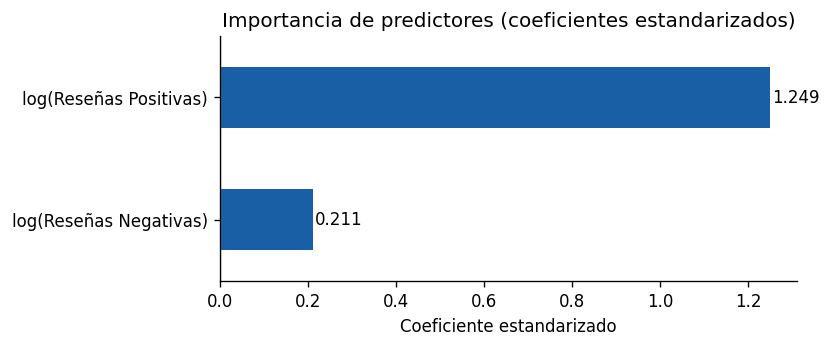

In [ ]:
from sklearn.preprocessing import StandardScaler

# Estandarizar para comparar coeficientes en misma escala
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)
model_std = LinearRegression().fit(X_scaled, y_train)

coefs = pd.Series(
    model_std.coef_,
    index=['log(Reseñas Positivas)', 'log(Reseñas Negativas)']
).sort_values()

fig, ax = plt.subplots(figsize=(7, 3))
colors = ['#185FA5' if c > 0 else '#D85A30' for c in coefs]
coefs.plot(kind='barh', ax=ax, color=colors, edgecolor='none')
ax.axvline(0, color='gray', linewidth=0.8)
ax.set_xlabel('Coeficiente estandarizado')
ax.set_title('Importancia de predictores (coeficientes estandarizados)')
ax.spines[['top','right']].set_visible(False)

for i, (idx, val) in enumerate(coefs.items()):
    ax.text(val + 0.005, i, f'{val:.3f}', va='center', fontsize=10)

plt.tight_layout()
plt.show()


#Reflexión final del análisis
El objetivo del trabajo fue construir un modelo capaz de predecir el pico de usuarios simultáneos (Peak CCU) de un videojuego en Steam a partir de sus reseñas positivas y negativas.

El primer hallazgo importante fue que las variables originales no podían usarse directamente: tanto el CCU como las reseñas siguen distribuciones extremadamente asimétricas, con unos pocos juegos enormemente populares y una gran mayoría con valores cercanos a cero. La transformación logarítmica fue el paso clave para hacer viable el análisis, convirtiendo relaciones exponenciales en relaciones lineales y estabilizando la varianza.

El modelo resultante explica el 52% de la varianza del log(Peak CCU), lo cual es un resultado sólido considerando que solo usa dos predictores. El coeficiente de las reseñas positivas (0.570) es notablemente mayor que el de las negativas (0.098), lo que sugiere que la popularidad de un juego — medida en usuarios simultáneos — está mucho más asociada al volumen de apoyo que recibe que a su controversia. Dicho de otro modo, tener muchas reseñas negativas no "arruina" el CCU tanto como tener reseñas positivas lo impulsa.

El 48% de varianza no explicada no es un fracaso del modelo: es una señal de que el CCU es un fenómeno complejo influido por factores que las reseñas no capturan, como el género del juego, las campañas de marketing, los streamers que lo popularizan, o simplemente el momento en que fue lanzado. Incorporar esas variables sería el paso natural para mejorar el modelo.

En definitiva, este trabajo demuestra que con técnicas estadísticas relativamente simples — transformación de variables, regresión lineal y diagnóstico de residuos — es posible extraer patrones significativos de un dataset con más de 120.000 juegos y construir una herramienta predictiva interpretable y útil.